 # ML Workflow

  Dataset
    →
  Understand columns
    →
  Clean data
    →
  Handle missing values
    →
  EDA
    →
  Identify target column
    →
  Separate X and y
    →
  Encode categorical columns
    →
  Train/Test Split
    →
  Feature Scaling (if required)
    →
  Train ML model
    →
  Prediction
    →
  Evaluate model

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [86]:
df = pd.read_table("/content/framingham.csv",sep=",")

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [88]:
df.isnull().sum()

,0
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50


In [89]:
null_cols = ["education", "cigsPerDay", "BPMeds", "totChol", "BMI", "heartRate", "glucose"]
for col in null_cols:
    df[col] = df[col].fillna(df[col].mean())

In [90]:
df.isnull().sum()

,0
male,0
age,0
education,0
currentSmoker,0
cigsPerDay,0
BPMeds,0
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,0


In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4238 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4238 non-null   float64
 5   BPMeds           4238 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4238 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4238 non-null   float64
 13  heartRate        4238 non-null   float64
 14  glucose          4238 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [92]:
df.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000,4238.00000,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.02963,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.007075,0.500024,11.879230,0.16852,0.076587,0.462763,0.158316,44.326453,22.038097,11.910850,4.070953,12.025177,22.836603,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.080000,68.000000,72.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.410000,75.000000,80.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.00000,0.000000,1.000000,0.000000,262.000000,144.000000,89.875000,28.037500,83.000000,85.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.00000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


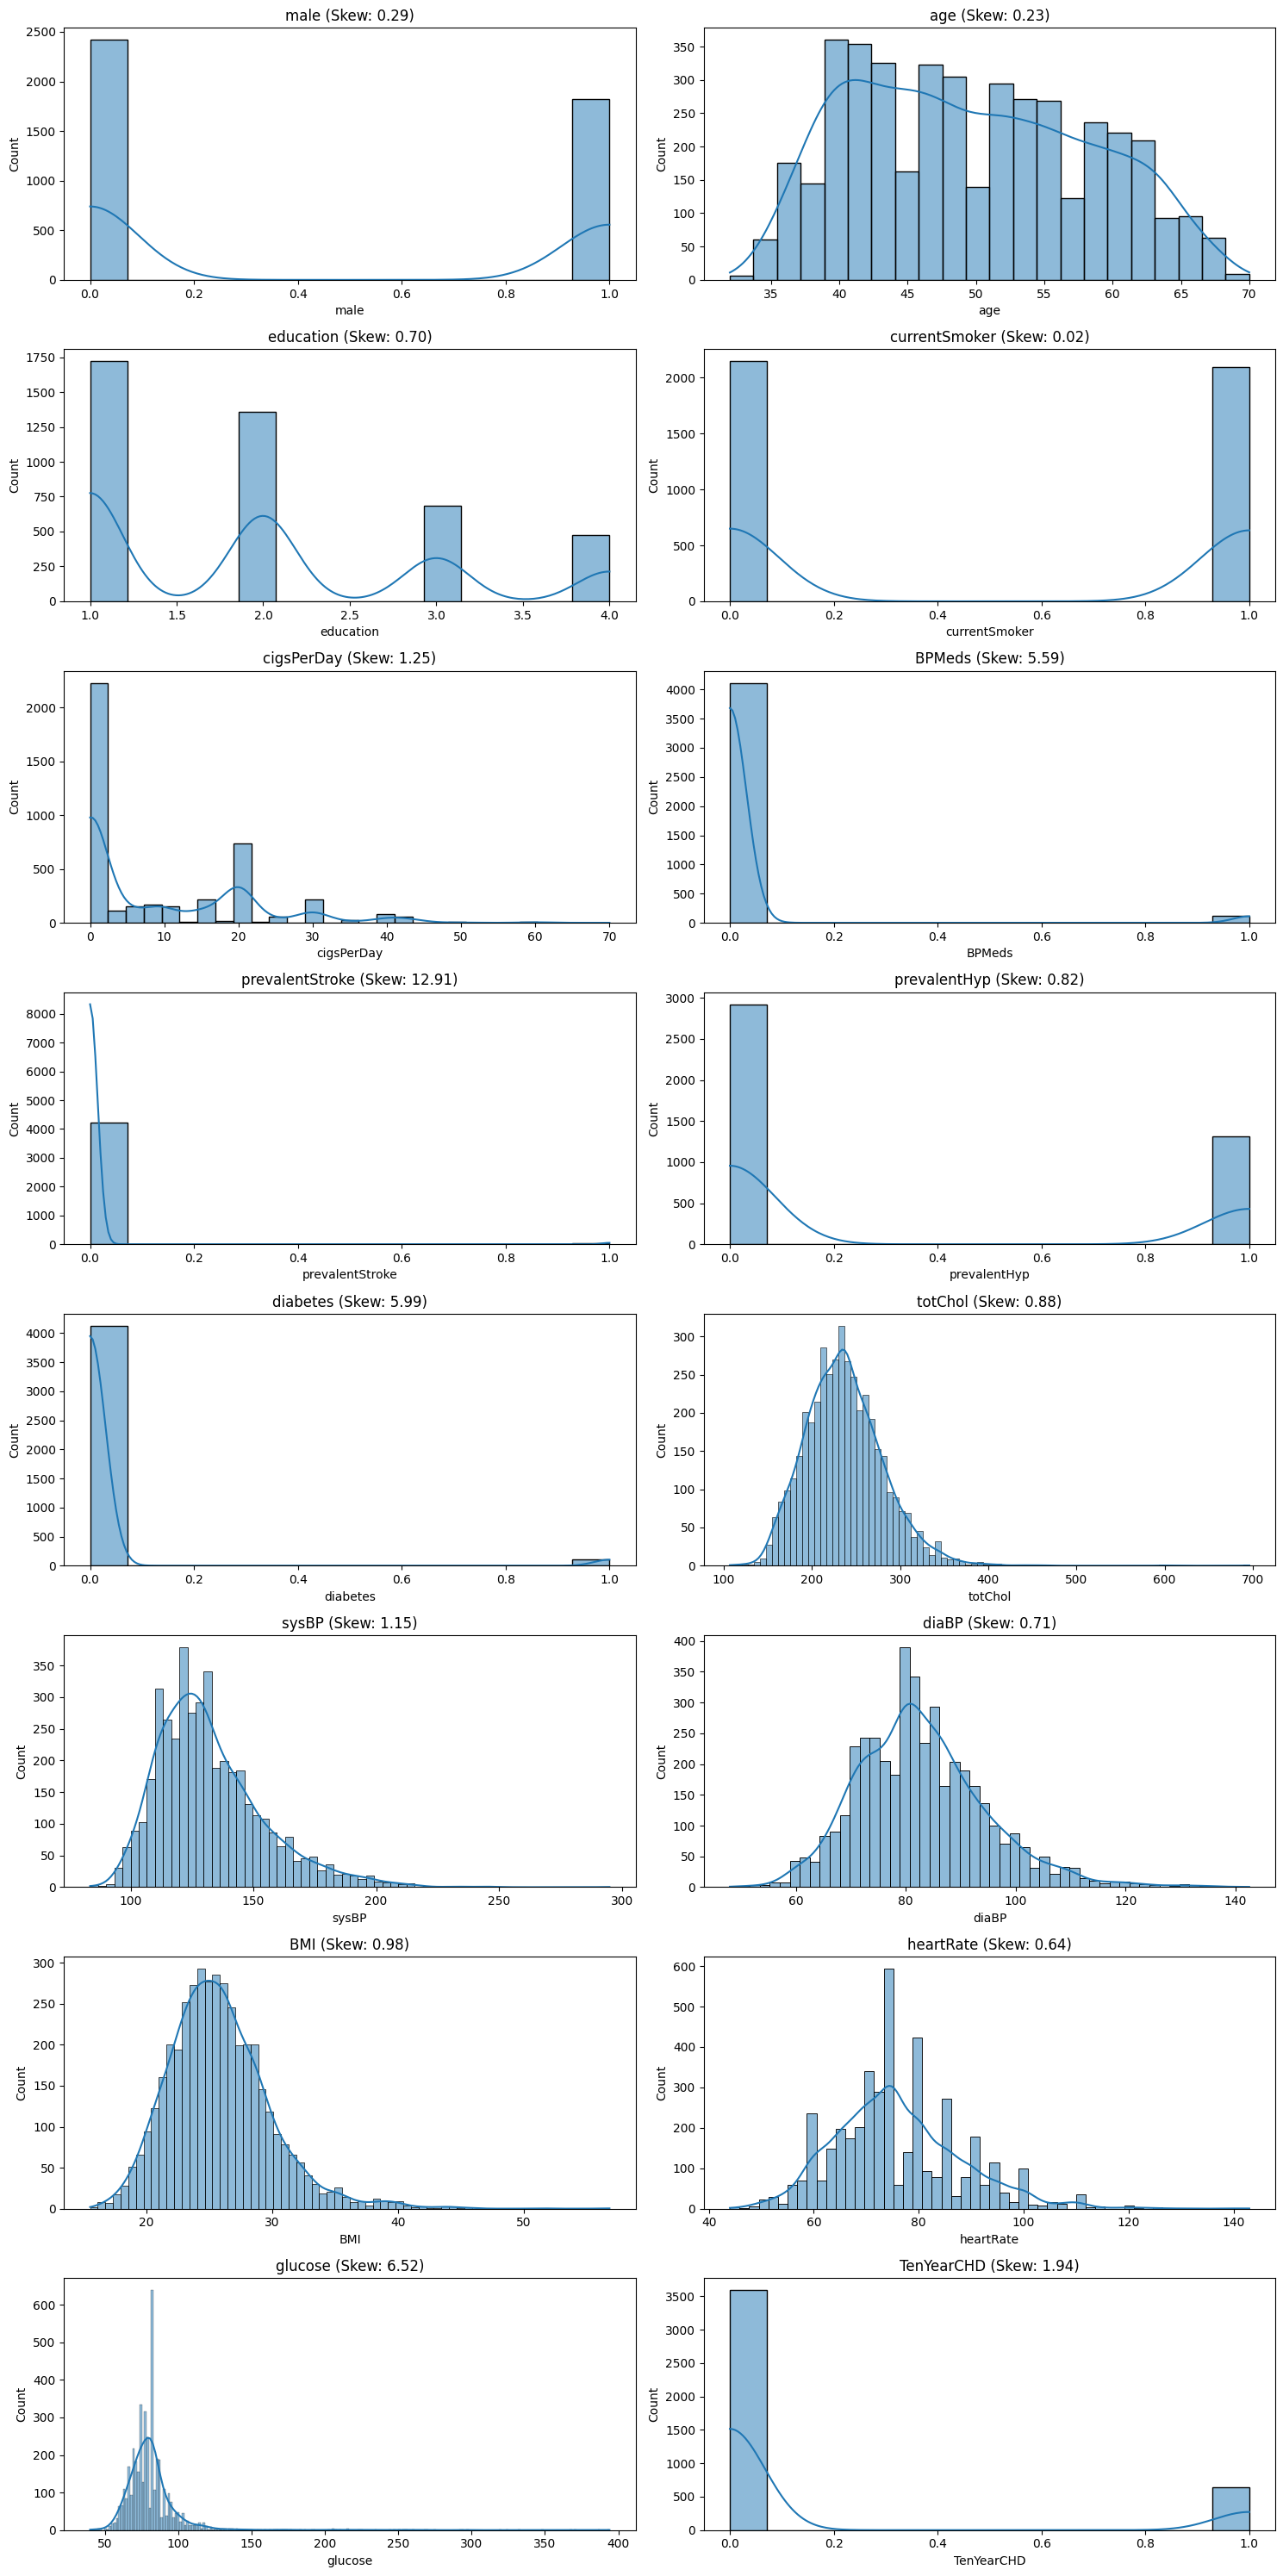

In [93]:
fig, axes = plt.subplots(8, 2, figsize=(15, 30))
for col, ax in zip(df.columns, axes.flatten()):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"{col} (Skew: {df[col].skew():.2f})")
plt.tight_layout()
plt.show()

In [94]:
x_df = df.iloc[ : , : -1]
y_df = df.iloc[ : , -1]

In [95]:
for i in x_df.columns:
  x_df[i] = np.log1p(df[i])

<Axes: >

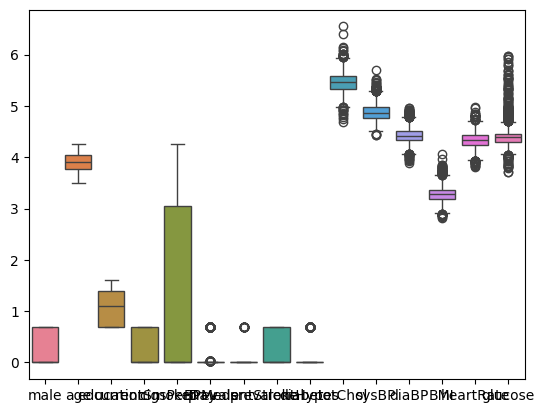

In [96]:
sns.boxplot(x_df)

In [97]:
%pip install -q outlier-tool-shashikant

In [98]:
from outlier_tool import Outliers
o = Outliers(x_df)

In [99]:
print(o.find("iqr"))

             column method     lower     upper  outliers  percent
0              male    iqr -1.039721  1.732868         0     0.00
1               age    iqr  3.338423  4.465828         0     0.00
2         education    iqr -0.346574  2.426015         0     0.00
3     currentSmoker    iqr -1.039721  1.732868         0     0.00
4        cigsPerDay    iqr -4.566784  7.611306         0     0.00
5            BPMeds    iqr  0.000000  0.000000       177     4.18
6   prevalentStroke    iqr  0.000000  0.000000        25     0.59
7      prevalentHyp    iqr -1.039721  1.732868         0     0.00
8          diabetes    iqr  0.000000  0.000000       109     2.57
9           totChol    iqr  4.973566  5.931307        35     0.83
10            sysBP    iqr  4.461611  5.285807        61     1.44
11            diaBP    iqr  4.062610  4.777605        67     1.58
12              BMI    iqr  2.900572  3.649398        78     1.84
13        heartRate    iqr  3.939041  4.725882        55     1.30
14        

In [100]:
df1 = o.iqr_cap()

<Axes: >

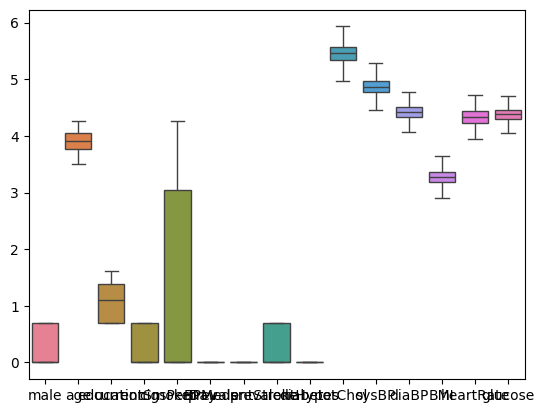

In [101]:
sns.boxplot(df1)

In [102]:
X = df1.iloc[ : , : -1]
Y = y_df

In [108]:
Y.value_counts()

,count
TenYearCHD,
0,3594
1,644


In [103]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [104]:
print(y_train.unique())

[0 1]


In [105]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, y_train)
accuracy = accuracy_score(y_test, lr.predict(X_test))
print(f"Accuracy: {accuracy}")
cm = confusion_matrix(y_test, lr.predict(X_test))
print(f"Confusion Matrix: \n{cm}")
cr = classification_report(y_test, lr.predict(X_test))
print(f"Classification Report: \n{cr}")
train = lr.score(X_train, y_train)
test = lr.score(X_test, y_test)
print(f"Train Accuracy: {train}")
print(f"Test Accuracy: {test}")

Accuracy: 0.8443396226415094
Confusion Matrix: 
[[715   4]
 [128   1]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.85      0.99      0.92       719
           1       0.20      0.01      0.01       129

    accuracy                           0.84       848
   macro avg       0.52      0.50      0.47       848
weighted avg       0.75      0.84      0.78       848

Train Accuracy: 0.8513274336283185
Test Accuracy: 0.8443396226415094


In [110]:
new = {}
for col in X.columns:
  value = input(f"Enter {col} ")
  if col in df.select_dtypes(include="number").columns:
    # Apply np.log1p transformation to align with the training data scaling
    new[col] = [np.log1p(float(value))]
  else:
    new[col] = [value]

new_df = pd.DataFrame(new)
predictions = lr.predict(new_df)[0]
probability = lr.predict_proba(new_df)[0]

if predictions == 1:
  print("\n\t Prediction: High risk of Coronary Heart Disease (CHD) in the next 10 years.")
else:
  print("\n\t Prediction: Low risk of Coronary Heart Disease (CHD) in the next 10 years.")

# Extract the probability of class 1 (at risk)
failure_probability = probability[1]
print(f"\t Risk Probability: {round(failure_probability * 100, 2)}%")

Enter male 1
Enter age 25
Enter education 12
Enter currentSmoker 2
Enter cigsPerDay 1
Enter BPMeds 0
Enter prevalentStroke 36
Enter prevalentHyp 100
Enter diabetes 0
Enter totChol 0
Enter sysBP 4
Enter diaBP 3
Enter BMI 3
Enter heartRate 4

	 Prediction: Low risk of Coronary Heart Disease (CHD) in the next 10 years.
	 Risk Probability: 0.97%
